In [1]:
from src.pruning_algorithms import *
from src.basis_functions import *
from src.dynamical_systems import *
from src.helper_functions import *
from utils import *
import time


 Data gathered. 
 Total data points:  49000


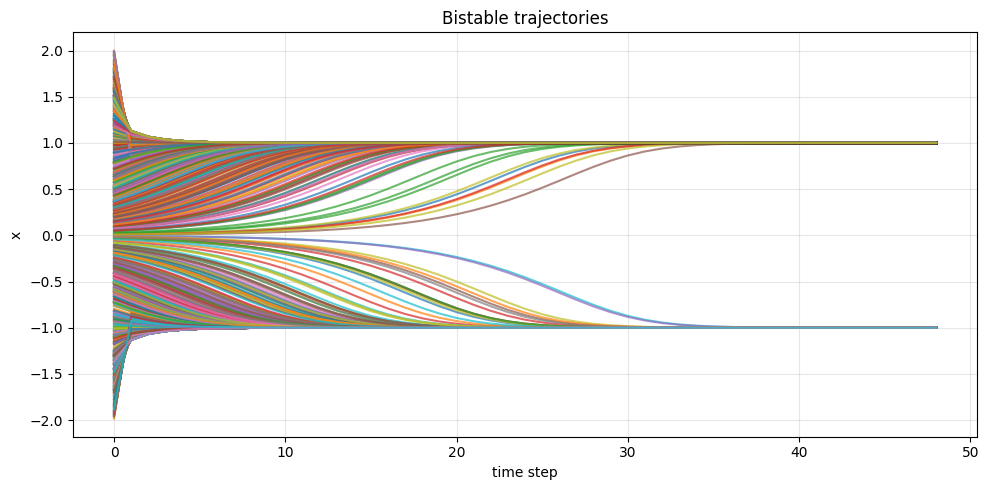

In [10]:
## Data Collection and Visualization
sys1 = systems(name = 'bistable')
n = sys1.n

traj_length = 50
N = 1000 * traj_length  # Total data points
#X1,Y1 = sys1.gather_data(num_samples= N, plot_results=False)
X2,Y2 = sys1.gather_traj_data(num_traj = N // traj_length, traj_length= traj_length, plot_results=True)
print(" Data gathered. ")

#X = np.vstack((X1,X2))
#Y = np.vstack((Y1,Y2))
X = X2
Y = Y2
print(" Total data points: ", X.shape[0])

X_data = X

# Plot the data as trajectories (1D state vs time step).
import numpy as np
import matplotlib.pyplot as plt

num_traj = N // traj_length
traj_data = X.reshape(num_traj, traj_length - 1, n)
t = np.arange(traj_length - 1)

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(num_traj):
    ax.plot(t, traj_data[i, :, 0], alpha=0.7)

ax.set_xlabel('time step')
ax.set_ylabel('x')
ax.set_title('Bistable trajectories')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
## Pick centers for the RBFs: K-means vs random subsample of data points.

n_global_centers = 500
use_kmeans_centers = True   # Set False to use random centers instead of K-means
random_center_seed = 42

centers_global = select_rbf_centers(
    X,
    n_global_centers,
    use_kmeans=use_kmeans_centers,
    random_state=random_center_seed,
)


Center selection: K-means (500 centers)
Time to compute K-means solution = 8.174 seconds
centers shape: (500, 1)


In [12]:
## Vanilla EDMD and coarse basin approximation

d_poly = 1
#poly = PolynomialBasis(n=sys1.n, d=d_poly)
Phi = build_thin_plate_dictionary(sys1.n, centers_global, d_poly=d_poly)
#Phi = poly
s = Phi.s
print(f'Number of Dictionary elements = {s}')

Phi_X = Phi.evaluate(X)
Phi_Y = Phi.evaluate(Y)
K_global = fit_edmd_operator(Phi_X, Phi_Y)

# Indicator eigenfunction (mu approx 1)
w_global, v_global = sorted_koopman_eigenmodes(K_global)


Number of Dictionary elements = 502
